In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import logomaker
import json

In [2]:
def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    # plt.ylim(min(df.sum(axis=1).min(), 0), df.sum(axis=1).max())
    # plt.ylim(df.sum(axis=1).max())
    ax.set_axis_off()
    # ax.set_ylim([0, 2])
    # ax.set_ylabel('bits')
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} {num_seqlets} {"{:.3e}".format(qval)}')
    # plt.show()

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

# Ramirez et al. (2018)

## Motif-6 (PPM)

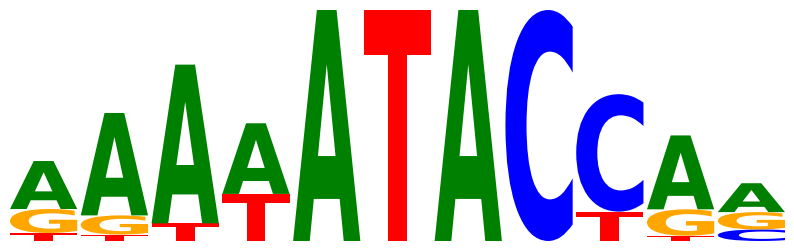

In [3]:
motif6_ppm = np.array([
    [0.6, 0.8, 0.9, 0.6, 1.0, 0.0, 1.0, 0.0, 0.0, 0.7, 0.5],   # A
    [0.0, 0.0, 0.00, 0.0, 0.0, 0.0, 0.0, 1.0, 0.8, 0.0, 0.2],  # C
    [0.3, 0.15, 0.00, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.25, 0.3],  # G
    [0.1, 0.05, 0.1, 0.4, 0.0, 1.0, 0.0, 0.0, 0.2, 0.05, 0.0]    # T
])

fig, ax = plt.subplots(1,1, figsize=(10,3))
plot_weights(make_logo(motif6_ppm.T), ax)

## Motif-7 (PPM)

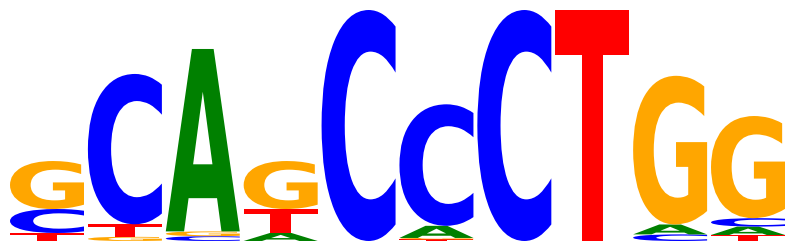

In [4]:
motif7_ppm = np.array([
    [0.0, 0.0, 0.95, 0.1, 0.0, 0.08, 0.0, 0.0, 0.06, 0.07],   # A
    [0.3, 0.9, 0.025, 0.0, 1.0, 0.8, 1.0, 0.0, 0.04, 0.07],  # C
    [0.6, 0.025, 0.025, 0.6, 0.0, 0.01, 0.0, 0.0, 0.9, 0.85],  # G
    [0.1, 0.075, 0.0, 0.3, 0.0, 0.01, 0.0, 1.0, 0.0, 0.05]    # T
])

fig, ax = plt.subplots(1,1, figsize=(10,3))
plot_weights(make_logo(motif7_ppm.T), ax)

## Ibf (PPM)

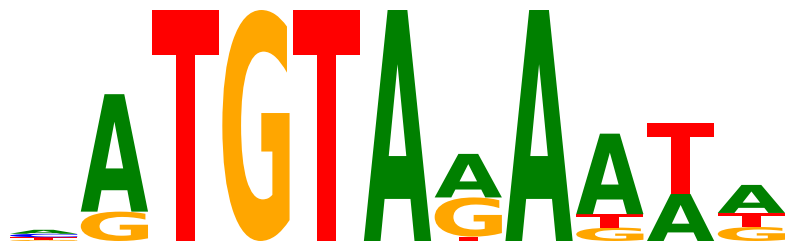

In [5]:
ibf_ppm = np.array([
    [0.375, 0.8, 0.0, 0.0, 0.0, 1.0, 0.5, 1.0, 0.75, 0.4, 0.5],   # A
    [0.325, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],  # C
    [0.1, 0.2, 0.0, 1.0, 0.0, 0.0, 0.45, 0.0, 0.125, 0.0, 0.25],  # G
    [0.25, 0.0, 1.0, 0.0, 1.0, 0.0, 0.05, 0.0, 0.125, 0.6, 0.25]    # T
])

fig, ax = plt.subplots(1,1, figsize=(10,3))
plot_weights(make_logo(ibf_ppm.T), ax)

## Vostok (PPM)

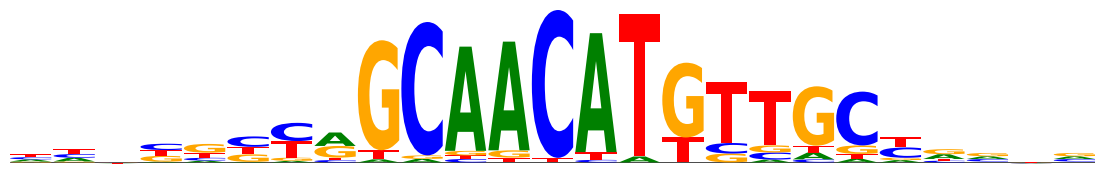

In [6]:
vostok_ppm = np.array([[0.275, 0.275, 0.1  , 0.35 ],
                    [0.275  , 0.275  , 0.07 , 0.38  ],
                    [0.24 , 0.24 , 0.24 , 0.28 ],
                    [0.04 , 0.34 , 0.31 , 0.31 ],
                    [0.1 , 0.15, 0.475  , 0.275],
                    [0.02 , 0.4 , 0.29 , 0.29],
                    [0.04 , 0.46 , 0.08 , 0.42],
                    [0.45 , 0.08 , 0.39 , 0.08 ],
                    [0.025, 0.   , 0.9  , 0.075 ],
                    [0.025, 0.95 , 0.025, 0.   ],
                    [0.9 , 0.03 , 0.04 , 0.03 ],
                    [0.9 , 0.   , 0.06 , 0.04 ],
                    [0.   , 0.97 , 0.   , 0.03 ],
                    [0.92 , 0.02 , 0.   , 0.06 ],
                    [0.04 , 0.   , 0.   , 0.96 ],
                    [0.   , 0.   , 0.75 , 0.25 ],
                    [0.   , 0.13 , 0.11 , 0.76 ],
                    [0.04 , 0.1  , 0.1  , 0.76 ],
                    [0.09 , 0.04 , 0.78 , 0.09 ],
                    [0.05 , 0.76 , 0.12 , 0.07 ],
                    [0.09 , 0.4  , 0.09 , 0.42 ],
                    [0.36 , 0.13 , 0.38 , 0.13 ],
                    [0.29 , 0.27 , 0.35 , 0.09 ],
                    [0.25   , 0.25   , 0.25   , 0.25  ],
                    [0.29 , 0.27 , 0.35 , 0.09 ]]).T

fig, ax = plt.subplots(1,1, figsize=(14,2))

# 9 12
plot_weights(make_logo(vostok_ppm.T), ax)

## Trem peak

This PWM was obtained from `/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/chip/motif8/trem/brendan_defined_peaks/meme_chip/trem_idr_summit_peaks_in_boundaries.q=0.01_memechip/combined.meme`. See `analyze_trem_peaks.ipynb` for more details.

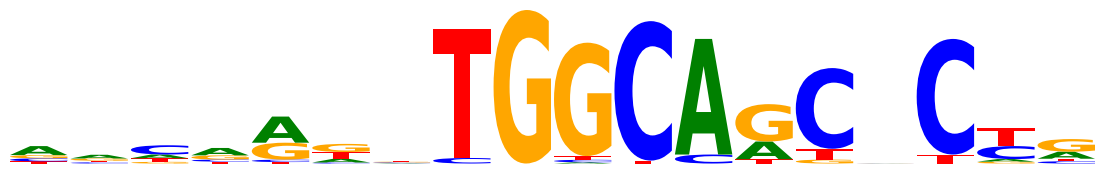

In [7]:
trem_ppm = np.array([[0.515464, 0.42268 , 0.206186, 0.474227, 0.556701, 0.185567,
        0.14433 , 0.      , 0.      , 0.010309, 0.      , 0.927835,
        0.298969, 0.      , 0.268041, 0.      , 0.072165, 0.28866 ],
       [0.175258, 0.134021, 0.505155, 0.134021, 0.051546, 0.051546,
        0.268041, 0.041237, 0.      , 0.020619, 0.979381, 0.072165,
        0.      , 0.845361, 0.278351, 0.927835, 0.360825, 0.092784],
       [0.185567, 0.257732, 0.092784, 0.268041, 0.360825, 0.412371,
        0.268041, 0.      , 1.      , 0.938144, 0.      , 0.      ,
        0.628866, 0.041237, 0.257732, 0.      , 0.051546, 0.515464],
       [0.123711, 0.185567, 0.195876, 0.123711, 0.030928, 0.350515,
        0.319588, 0.958763, 0.      , 0.030928, 0.020619, 0.      ,
        0.072165, 0.113402, 0.195876, 0.072165, 0.515464, 0.103093]])

fig, ax = plt.subplots(1,1, figsize=(14,2))

# 9 12
plot_weights(make_logo(trem_ppm.T), ax)

# Qi et. al. (2022)


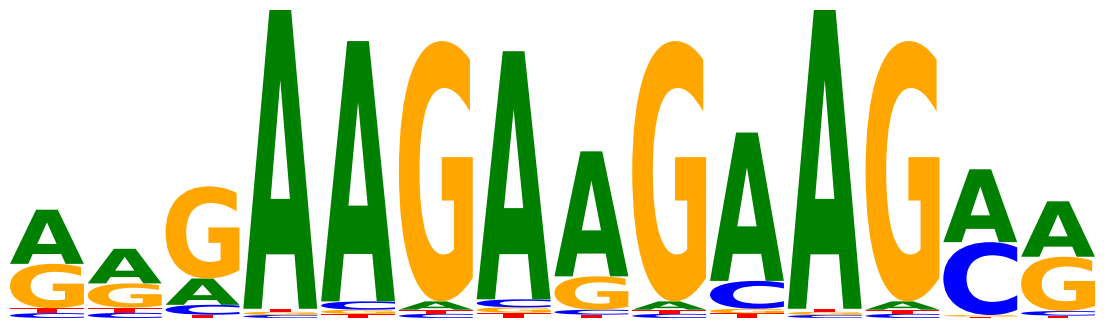

In [8]:
aag3_ppm = np.array([[0.55, 0.05, 0.45  , 0.05 ],
                    [0.5  , 0.075  , 0.35 , 0.075  ],
                    [0.2 , 0.075 , 0.7 , 0.025 ],
                    [0.97 , 0.01 , 0.01 , 0.01 ],
                    [0.94 , 0.03 , 0.015 , 0.015 ],
                    [0.03 , 0.015, 0.94 , 0.015],
                    [0.93 , 0.03 , 0.02 , 0.02],
                    [0.75 , 0.03 , 0.2 , 0.02 ],
                    [0.03 , 0.015, 0.94 , 0.015],
                    [0.8 , 0.15 , 0.025 , 0.025 ],
                    [0.97 , 0.01 , 0.01 , 0.01 ],
                    [0.03 , 0.015, 0.94 , 0.015],
                    [0.49 , 0.49 , 0.01 , 0.01],
                    [0.475 , 0.04 , 0.465,  0.02 ]]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(aag3_ppm.T), ax)

# Mulberry (Umemura et al. 2026)

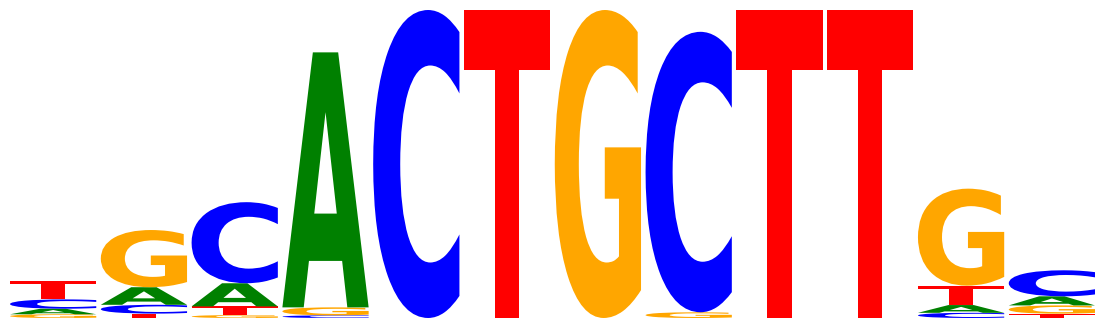

In [9]:
                        # A    # C     # G     # T
mulberry_ppm = np.array([
                        [0.15, 0.25, 0.1  , 0.5 ],
                        [0.2 , 0.1  , 0.65 , 0.05  ],
                        [0.2 , 0.7 , 0.025 , 0.075 ],
                        [0.96 , 0.01 , 0.03 , 0 ],
                        [0.0 , 1.0 , 0.0 , 0.0 ],
                        [0.0 , 0.0, 0.0 , 1.0],
                        [0.0 , 0.0 , 1.0 , 0.0],
                        [0.0 , 0.98 , 0.02 , 0.0 ],
                        [0.0 , 0.0, 0.0 , 1.0],
                        [0.0 , 0.0 , 0.0 , 1.0 ],
                        [0.06 , 0.04 , 0.75 , 0.15 ],
                        [0.21 , 0.6 , 0.19,  0.1 ]
                    ]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(mulberry_ppm.T), ax)

# GAGA (Tsai et al. 2016)

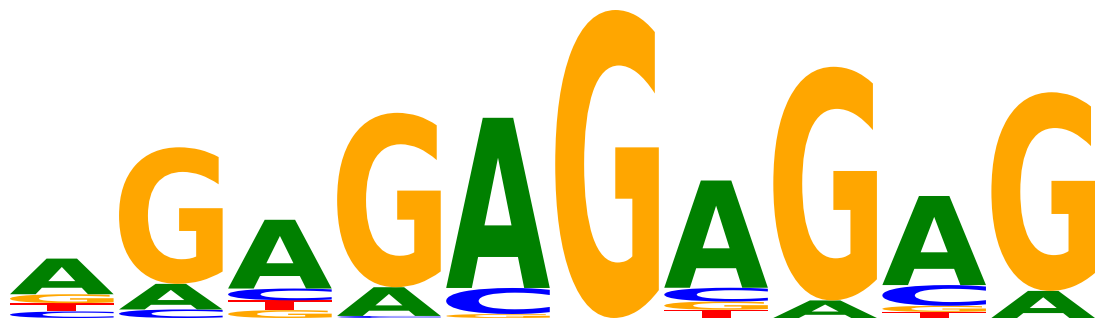

In [10]:
                        # A    # C     # G     # T
gaga_ppm = np.array([
                        [0.6, 0.11, 0.15  , 0.14 ],
                        [0.15 , 0.05  , 0.8 , 0  ],
                        [0.7 , 0.12 , 0.08 , 0.1 ],
                        [0.14 , 0.01  , 0.85 , 0  ],
                        [0.85 , 0.13  , 0.02 , 0  ],
                        [0.0 , 0.0, 1.0 , 0.0],
                        [0.78 , 0.1 , 0.06 , 0.06 ],
                        [0.07 , 0.0 , 0.93 , 0.0 ],
                        [0.73 , 0.17, 0.05 , 0.05],
                        [0.12 , 0.0 , 0.88 , 0.0 ],
                    ]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(gaga_ppm.T), ax)

# Lola-D (zf.princeton.edu)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


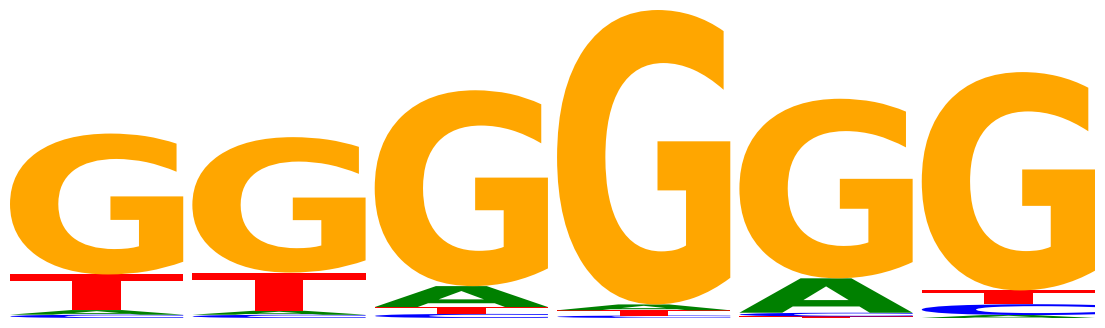

In [34]:
lolad_ppm = np.array([
    [0.025, 0.018, 0.764, 0.193],  # position 1
    [0.022, 0.018, 0.749, 0.211],  # position 2
    [0.092, 0.018, 0.860, 0.030],  # position 3
    [0.019, 0.008, 0.955, 0.017],  # position 4
    [0.157, 0.017, 0.819, 0.007],  # position 5
    [0.012, 0.044, 0.887, 0.056],  # position 6
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolad_ppm.T), ax)



# Lola-I (zf.princeton.edu)

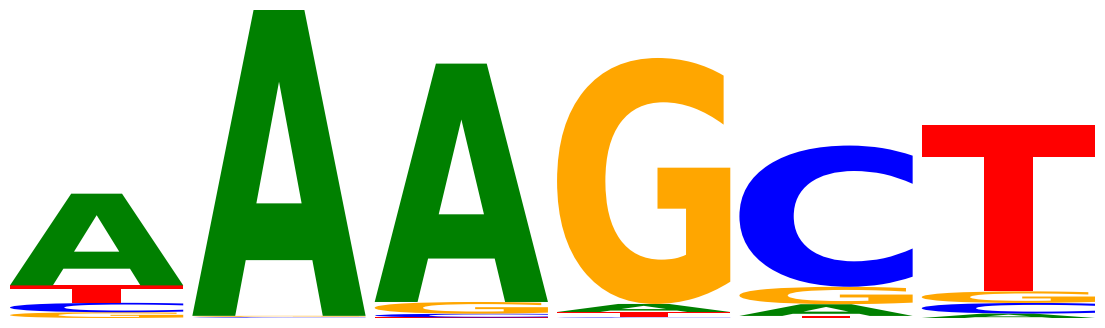

In [35]:
lolaI_ppm = np.array([
    [0.737, 0.076, 0.046, 0.140],  # position 1
    [0.994, 0.002, 0.003, 0.002],  # position 2
    [0.937, 0.015, 0.046, 0.002],  # position 3
    [0.031, 0.002, 0.946, 0.021],  # position 4
    [0.068, 0.819, 0.101, 0.012],  # position 5
    [0.023, 0.055, 0.060, 0.863],  # position 6
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaI_ppm.T), ax)

## Lola-N (zf.princeton.edu)

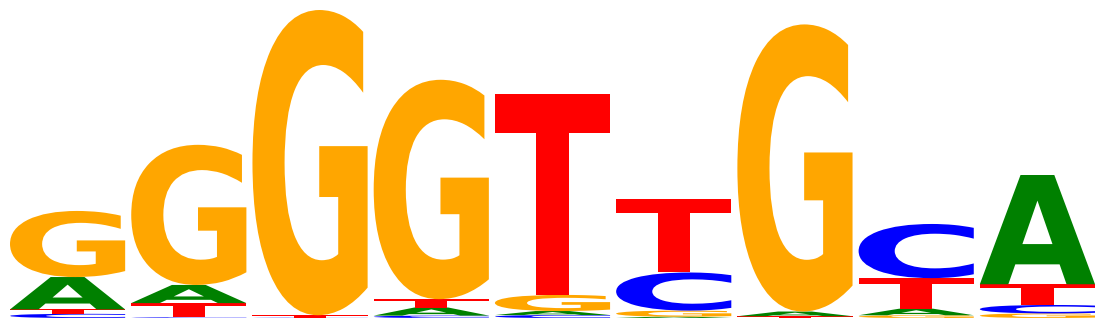

In [36]:
lolaN_ppm = np.array([
    [0.303, 0.039, 0.618, 0.041],
    [0.105, 0.004, 0.810, 0.082],
    [0.000, 0.001, 0.990, 0.008],
    [0.034, 0.010, 0.920, 0.035],
    [0.018, 0.013, 0.072, 0.897],
    [0.011, 0.319, 0.051, 0.618],
    [0.016, 0.000, 0.978, 0.006],
    [0.070, 0.576, 0.029, 0.325],
    [0.764, 0.059, 0.032, 0.145]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaN_ppm.T), ax)

## Lola-O

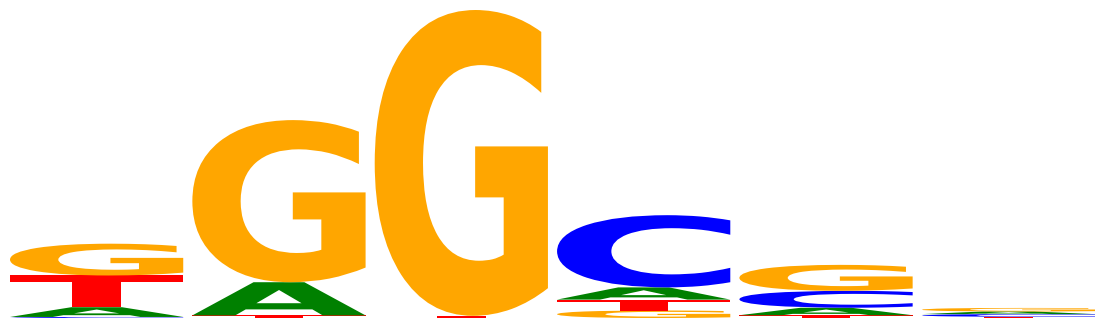

In [37]:
lolaO_ppm = np.array([
    [0.131, 0.014, 0.428, 0.427],
    [0.168, 0.000, 0.820, 0.013],
    [0.000, 0.000, 0.993, 0.007],
    [0.119, 0.703, 0.073, 0.106],
    [0.141, 0.319, 0.489, 0.052],
    [0.264, 0.259, 0.352, 0.126]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaO_ppm.T), ax)

## Lola-W

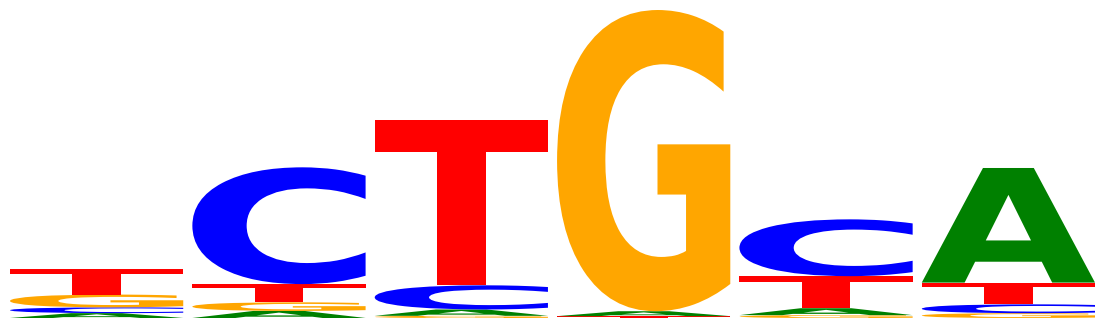

In [39]:
lolaW_ppm = np.array([
    [0.100, 0.119, 0.263, 0.518],
    [0.047, 0.775, 0.057, 0.121],
    [0.032, 0.122, 0.011, 0.835],
    [0.016, 0.000, 0.978, 0.006],
    [0.070, 0.576, 0.029, 0.325],
    [0.764, 0.059, 0.032, 0.145]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaW_ppm.T), ax)

## Lola-Y 

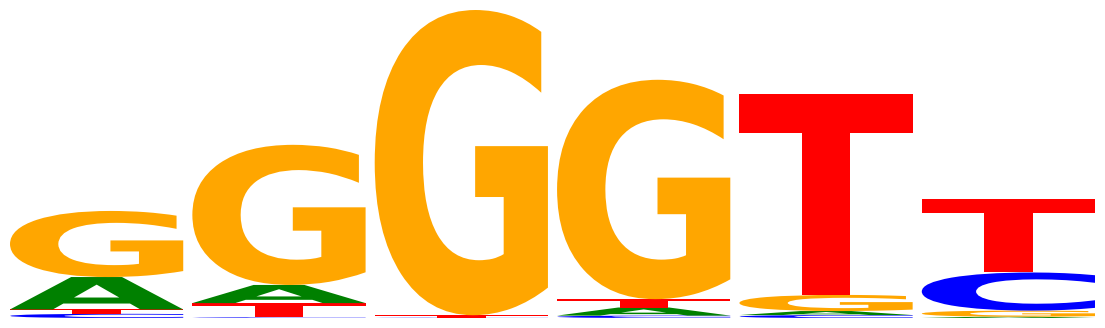

In [40]:
lolaY_ppm = np.array([
    [0.303, 0.039, 0.618, 0.041],
    [0.105, 0.004, 0.810, 0.082],
    [0.000, 0.001, 0.990, 0.008],
    [0.034, 0.010, 0.920, 0.035],
    [0.018, 0.013, 0.072, 0.897],
    [0.011, 0.319, 0.051, 0.618]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaY_ppm.T), ax)

## Lola-B

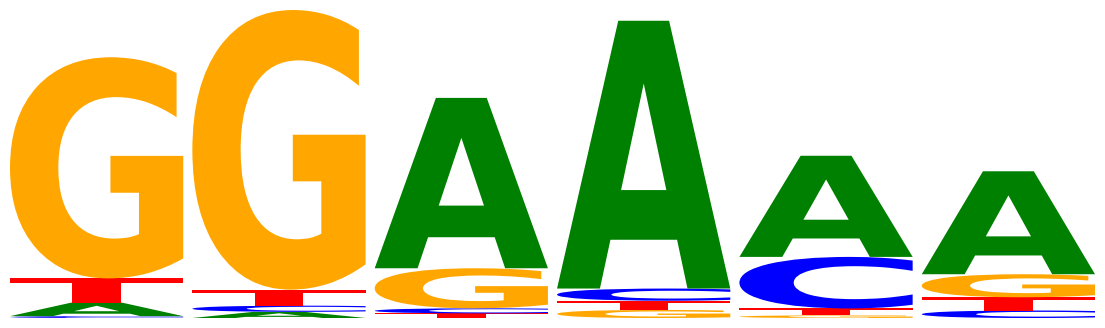

In [41]:
lolaB_ppm = np.array([
    [0.052, 0.007, 0.849, 0.093],
    [0.020, 0.020, 0.908, 0.052],
    [0.774, 0.023, 0.182, 0.021],
    [0.900, 0.041, 0.027, 0.031],
    [0.624, 0.318, 0.016, 0.043],
    [0.701, 0.051, 0.157, 0.090]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaB_ppm.T), ax)

## Lola-A

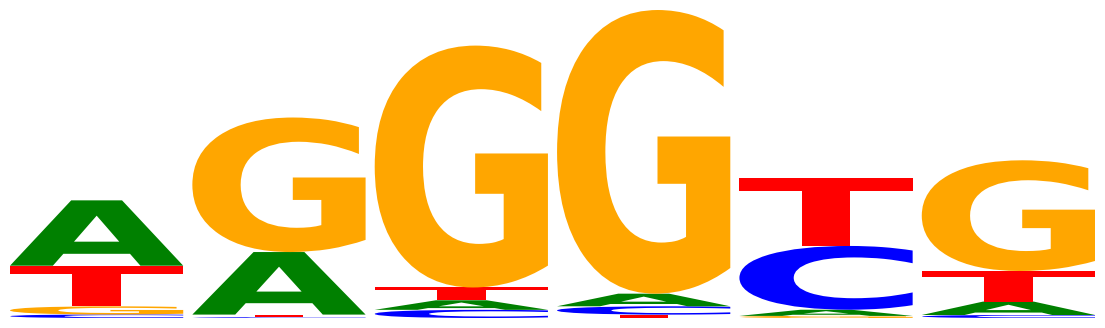

In [42]:
lolaA_ppm = np.array([
    [0.555, 0.030, 0.069, 0.345],
    [0.312, 0.004, 0.671, 0.013],
    [0.035, 0.030, 0.888, 0.047],
    [0.041, 0.027, 0.921, 0.011],
    [0.044, 0.455, 0.015, 0.486],
    [0.085, 0.019, 0.702, 0.194]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaA_ppm.T), ax)

## Lola-L

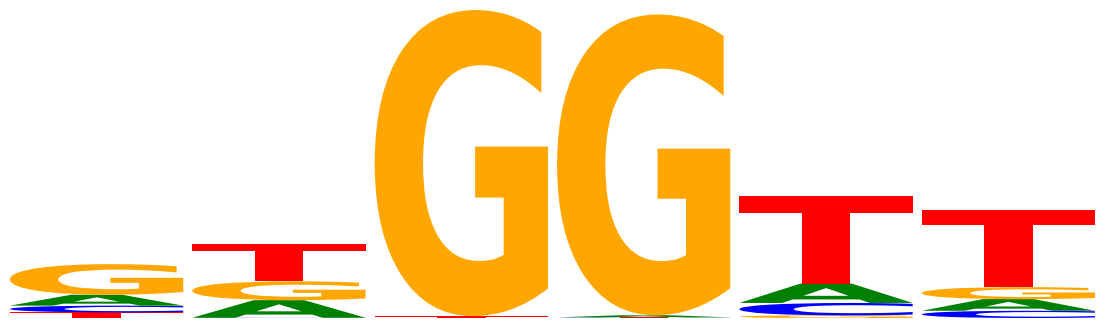

In [43]:
lolaL_ppm = np.array([
    [0.202, 0.125, 0.568, 0.104],
    [0.238, 0.003, 0.255, 0.504],
    [0.000, 0.000, 0.994, 0.006],
    [0.007, 0.001, 0.991, 0.001],
    [0.159, 0.102, 0.021, 0.719],
    [0.108, 0.067, 0.111, 0.714]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaL_ppm.T), ax)

## Lola-F

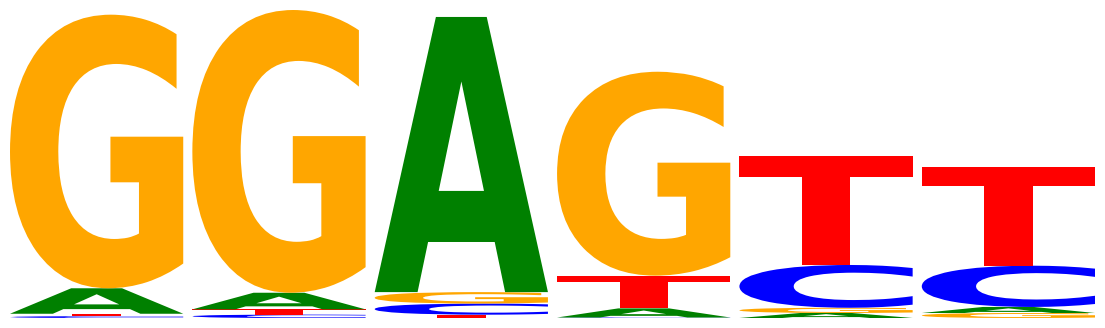

In [44]:
lolaF_ppm = np.array([
    [0.084, 0.006, 0.902, 0.008],
    [0.054, 0.011, 0.918, 0.017],
    [0.914, 0.037, 0.038, 0.011],
    [0.037, 0.002, 0.828, 0.133],
    [0.031, 0.263, 0.032, 0.673],
    [0.040, 0.273, 0.033, 0.654]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaF_ppm.T), ax)

## Lola-K

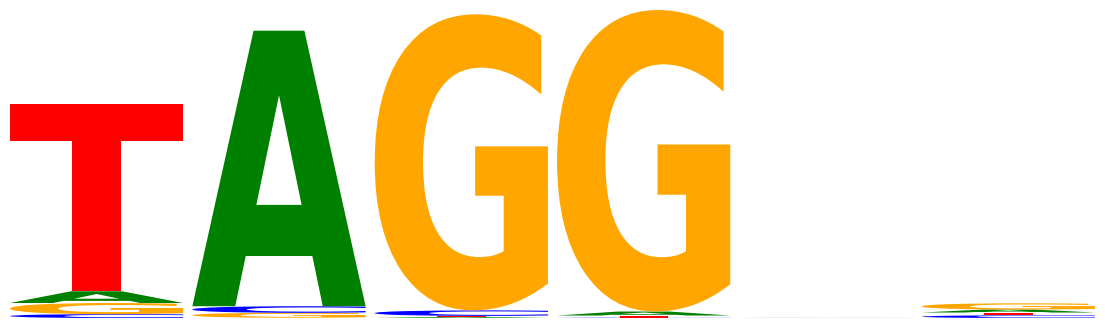

In [45]:
lolaK_ppm = np.array([
    [0.055, 0.018, 0.052, 0.875],
    [0.959, 0.023, 0.017, 0.001],
    [0.003, 0.018, 0.975, 0.004],
    [0.013, 0.001, 0.979, 0.007],
    [0.280, 0.213, 0.301, 0.206],
    [0.203, 0.180, 0.424, 0.193]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaK_ppm.T), ax)

## Lola-T

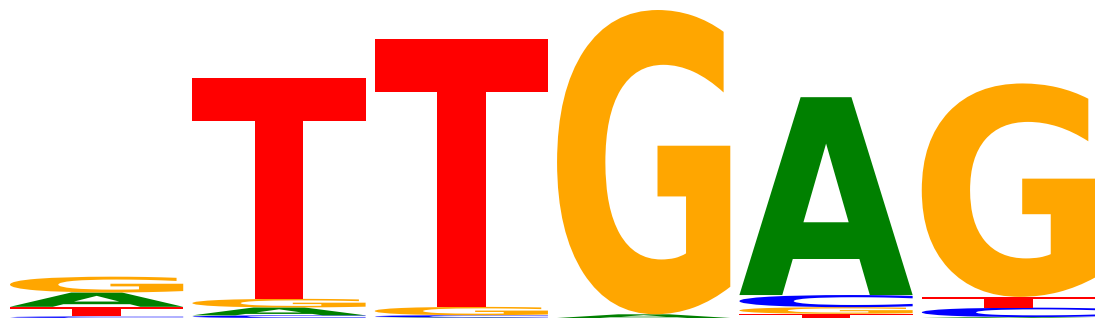

In [46]:
lolaT_ppm = np.array([
    [0.346, 0.038, 0.383, 0.233],
    [0.033, 0.011, 0.036, 0.920],
    [0.002, 0.008, 0.030, 0.961],
    [0.012, 0.000, 0.987, 0.000],
    [0.896, 0.055, 0.030, 0.019],
    [0.004, 0.040, 0.909, 0.046]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaT_ppm.T), ax)

## Lola-P

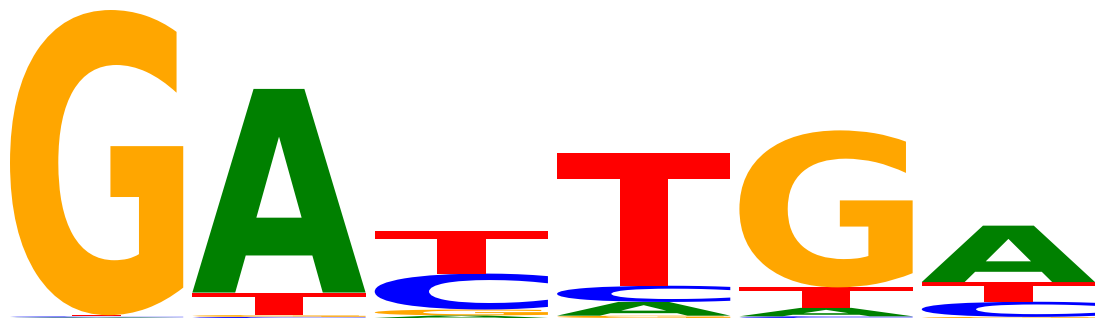

In [47]:
lolaP_ppm = np.array([
    [0.002, 0.003, 0.991, 0.004],
    [0.889, 0.005, 0.008, 0.098],
    [0.030, 0.413, 0.068, 0.489],
    [0.083, 0.098, 0.014, 0.805],
    [0.045, 0.009, 0.836, 0.109],
    [0.611, 0.164, 0.012, 0.213]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaP_ppm.T), ax)

## Lola-J

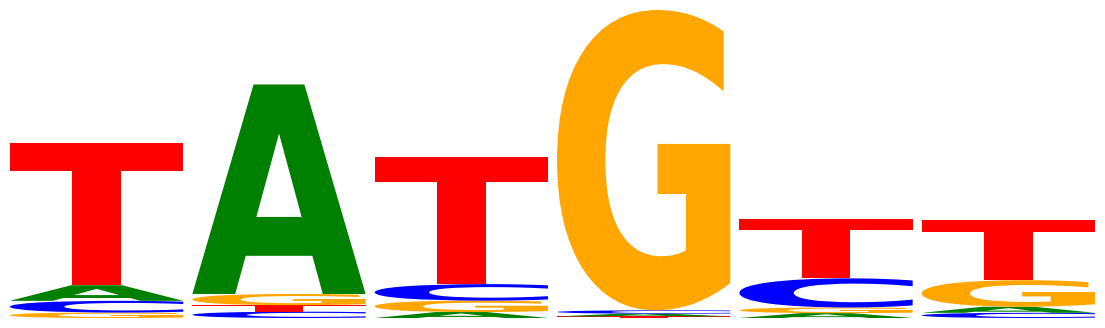

In [48]:
lolaJ_ppm = np.array([
    [0.089, 0.067, 0.031, 0.813],
    [0.898, 0.027, 0.048, 0.028],
    [0.037, 0.103, 0.071, 0.789],
    [0.009, 0.011, 0.976, 0.005],
    [0.049, 0.294, 0.057, 0.601],
    [0.062, 0.053, 0.271, 0.614]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaJ_ppm.T), ax)

## Lola-Q

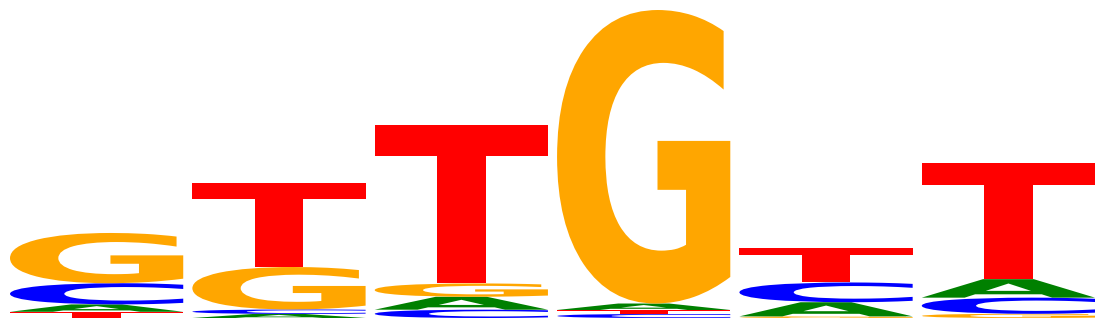

In [49]:
lolaQ_ppm = np.array([
    [0.087, 0.249, 0.591, 0.073],
    [0.030, 0.033, 0.314, 0.624],
    [0.067, 0.043, 0.069, 0.821],
    [0.021, 0.013, 0.953, 0.013],
    [0.202, 0.282, 0.023, 0.493],
    [0.119, 0.104, 0.027, 0.750]
]).T

fig, ax = plt.subplots(1,1, figsize=(14,4))

# 9 12
plot_weights(make_logo(lolaQ_ppm.T), ax)

## Save to dict

In [50]:
external_ppms = {
    'Motif-6': motif6_ppm.tolist(),
    'Motif-7': motif7_ppm.tolist(),
    'Ibf': ibf_ppm.tolist(),
    'Vostok': vostok_ppm.tolist(),
    'Trem': trem_ppm.tolist(),
    'AAG3': aag3_ppm.tolist(),
    'Mulberry': mulberry_ppm.tolist(),
    'GAGA1': gaga_ppm.tolist(),
    'GAGA2': gaga_ppm.tolist(),
    'Lola-D': lolad_ppm.tolist(),
    'Lola-I': lolaI_ppm.tolist(),
    'Lola-N': lolaN_ppm.tolist(),
    'Lola-J': lolaJ_ppm.tolist(),
    'Lola-Q': lolaQ_ppm.tolist(),
    'Lola-P': lolaP_ppm.tolist(),
    'Lola-T': lolaT_ppm.tolist(),
    'Lola-K': lolaK_ppm.tolist(),
    'Lola-F': lolaF_ppm.tolist(),
    'Lola-L': lolaL_ppm.tolist(),
    'Lola-A': lolaA_ppm.tolist(),
    'Lola-B': lolaB_ppm.tolist(),
    'Lola-B': lolaB_ppm.tolist(),
    'Lola-Y': lolaY_ppm.tolist(),
    'Lola-W': lolaW_ppm.tolist(),
    'Lola-O': lolaO_ppm.tolist(),
}

with open('external_ppms.json', 'w') as f:
    json.dump(external_ppms, f)